# Etapa 1: Pré-processamento de Linguagem Natural (NLP) para KDD
Este notebook inicia a fase de transformação de dados do processo KDD. Vamos focar na limpeza profunda dos resumos acadêmicos (`DS_RESUMO`) da CAPES utilizando a biblioteca `spaCy`. 
A lematização e a remoção de *stopwords* (incluindo jargões acadêmicos) são fundamentais para garantir que modelos como o BERTopic identifiquem tendências reais de pesquisa (como a ascensão da Inteligência Artificial) em vez de ruídos sintáticos.

In [1]:
# Instalação das dependências necessárias
# python -m spacy download pt_core_news_sm

import pandas as pd
import spacy
import re
import os
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

# Configuração visual dos gráficos
sns.set_theme(style="whitegrid")
print("Bibliotecas importadas com sucesso!")

Bibliotecas importadas com sucesso!


## 1. Carregamento da Base de Dados
Vamos ler o CSV gerado pelo script `limpeza_planilhas.py`. Como este notebook ficará salvo na pasta `notebooks/`, utilizamos o caminho relativo `../data/` para acessar a base.

In [2]:
# Carregar os dados limpos
caminho_dados = '../data/dados_capes_computacao_2010_2024.csv.gz'
df = pd.read_csv(caminho_dados, compression='gzip')

print(f"Total de trabalhos carregados: {len(df)}")
df.head(3)

Total de trabalhos carregados: 23897


,AN_BASE,NM_REGIAO,SG_ENTIDADE_ENSINO,NM_PROGRAMA,NM_AREA_AVALIACAO,NM_PRODUCAO,NM_GRAU_ACADEMICO,DS_PALAVRA_CHAVE,DS_RESUMO
0,2012,NORTE,UFAM,INFORMÁTICA,CIÊNCIA DA COMPUTAÇÃO,Sistema Inteligente de Recomendação Baseado n...,MESTRADO,"Agentes, ontologia, Modelo de aluno",Com a disseminação dos cursos de Educação a Di...
1,2012,NORTE,UFAM,INFORMÁTICA,CIÊNCIA DA COMPUTAÇÃO,Alinhamento Espaço-Temporal em Sistemas Multis...,MESTRADO,"Alinhamento espaço-temporal, Integração de dados",Este trabalho apresenta a utilização de difere...
2,2012,NORTE,UFAM,INFORMÁTICA,CIÊNCIA DA COMPUTAÇÃO,''UBICUA: Uma Técnica de Inspeção de Usabilida...,MESTRADO,"Usabilidade,Aplicações Web Móveis,Inspeção de ...",O crescente interesse em tecnologias móveis e ...


## 2. Limpeza de Texto com spaCy
Aqui construímos o *pipeline* de NLP. A função definida abaixo removerá pontuações, números e palavras comuns (*stopwords*). Também aplicará a **lematização**, transformando palavras flexionadas em sua raiz (ex: "modelando" vira "modelar", "redes" vira "rede"). Isso reduz a dimensionalidade dos dados e melhora a qualidade da modelagem de tópicos.

In [3]:
# Carregar o modelo de linguagem em português do spaCy
try:
    nlp = spacy.load("pt_core_news_sm")
except OSError:
    print("Modelo 'pt_core_news_sm' não encontrado. Rode: python -m spacy download pt_core_news_sm no terminal.")

# Adição de stopwords específicas do domínio acadêmico e verbos genéricos
stopwords_academicas = {
    'tese', 'dissertação', 'trabalho', 'estudo', 'pesquisa', 'objetivo', 
    'proposta', 'apresentar', 'mostrar', 'capítulo', 'análise', 'resultado',
    'conclusão', 'base', 'dados', 'método', 'problema', 'contexto',
    'utilizar', 'ser', 'processo', 'propor', 'abordagem', 'realizar',
    'basear', 'uso', 'conjunto', 'aplicação', 'de', 'obter', 'avaliar', 'algoritmo'
}

for word in stopwords_academicas:
    nlp.vocab[word].is_stop = True

def limpar_texto(texto):
    if not isinstance(texto, str):
        return ""
    
    texto = re.sub(r'\s+', ' ', texto)
    doc = nlp(texto.lower())
    tokens_limpos = []
    
    for token in doc:
        # Trava 1: Verifica o tamanho e se a palavra original não é stopword
        if not token.is_stop and not token.is_punct and token.is_alpha and len(token.lemma_) > 2:
            # Trava 2: Verifica se o LEMA da palavra não está na nossa lista customizada
            if token.lemma_ not in stopwords_academicas:
                tokens_limpos.append(token.lemma_)
            
    return " ".join(tokens_limpos)

print("Iniciando o pré-processamento. Isso pode levar alguns minutos...")

# Aplica a função em toda a coluna de resumos
df['RESUMO_LIMPO'] = df['DS_RESUMO'].apply(limpar_texto)

print("Limpeza concluída!")
df[['DS_RESUMO', 'RESUMO_LIMPO']].head(3)

Iniciando o pré-processamento. Isso pode levar alguns minutos...
Limpeza concluída!


,DS_RESUMO,RESUMO_LIMPO
0,Com a disseminação dos cursos de Educação a Di...,disseminação curso educação distância frequent...
1,Este trabalho apresenta a utilização de difere...,utilização diferentes sensor aprimoramento inf...
2,O crescente interesse em tecnologias móveis e ...,crescente interesse tecnologia móvel evolutivo...


## 3. Análise Exploratória (EDA) dos Termos
Para validar se nossa limpeza foi bem-sucedida, vamos visualizar a frequência das palavras remanescentes. Se palavras muito genéricas ainda aparecerem no topo, podemos voltar e adicioná-las na nossa lista de `stopwords_academicas`.

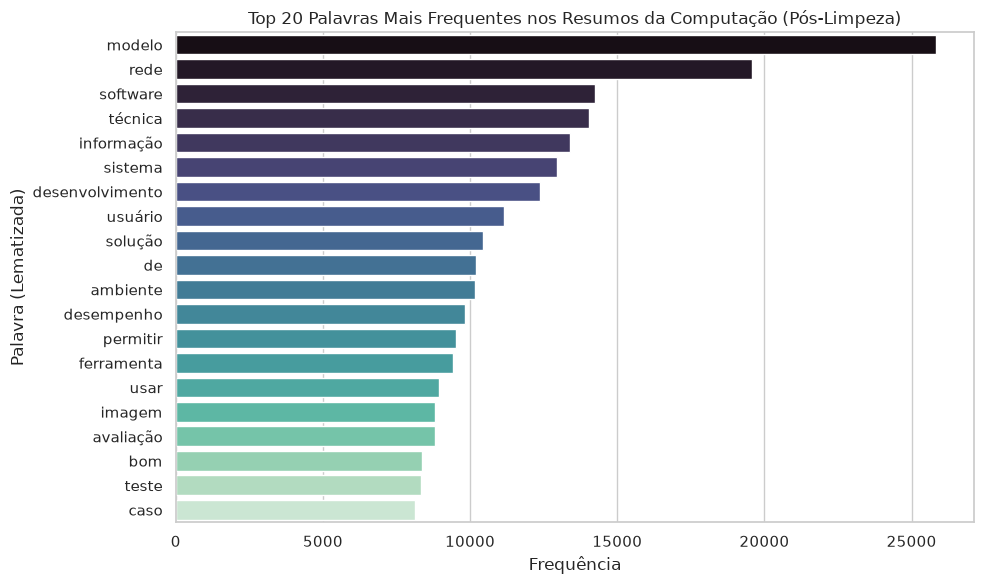

In [4]:
# Juntar todos os textos limpos para contagem global
todas_palavras = " ".join(df['RESUMO_LIMPO'].dropna()).split()

# Contar frequências
contagem = Counter(todas_palavras)
palavras_comuns = contagem.most_common(20)
df_freq = pd.DataFrame(palavras_comuns, columns=['Palavra', 'Frequência'])

# Plotagem do gráfico de barras horizontais
plt.figure(figsize=(10, 6))
sns.barplot(x='Frequência', y='Palavra', data=df_freq, palette='mako', hue='Palavra', legend=False)
plt.title('Top 20 Palavras Mais Frequentes nos Resumos da Computação (Pós-Limpeza)')
plt.xlabel('Frequência')
plt.ylabel('Palavra (Lematizada)')
plt.tight_layout()

# Garante que a pasta 'figuras' exista dentro de 'data'
caminho_pasta_figuras = '../data/figuras'
os.makedirs(caminho_pasta_figuras, exist_ok=True)

# Salva a imagem em alta resolução no diretório correto
plt.savefig(f'{caminho_pasta_figuras}/top20_palavras_frequentes.png', dpi=300, bbox_inches='tight')

plt.show()

## 4. Exportação do Dataset Processado
Agora que os dados textuais estão limpos e padronizados, vamos exportá-los. Este novo arquivo será a base de entrada para o nosso próximo notebook, onde finalmente aplicaremos o BERTopic para mapear a ascensão da Inteligência Artificial.

In [5]:
# Exportar CSV para alimentar a modelagem de tópicos
# Muda a extensão para .csv.gz e adiciona o parâmetro de compressão
caminho_saida = '../data/dados_capes_nlp.csv.gz'
df.to_csv(caminho_saida, index=False, encoding='utf-8', compression='gzip')
print(f"Base NLP processada e salva com sucesso em: {caminho_saida}")

Base NLP processada e salva com sucesso em: ../data/dados_capes_nlp.csv.gz
